# 004a. Cubic perturbation theory for a strongly anharmonic system: $^3E \rightarrow {}^1A_1$ of NV$^-$ in MgO

Tutorial 004 applied the first-order cubic correction to NV$^-$ in diamond, a weakly anharmonic system, where it works
very well. This notebook repeats the **same analysis** on the intersystem crossing $^3E \rightarrow {}^1A_1$ of NV$^-$ in
MgO (the system of Tutorial 003), whose potential energy surfaces (PES) are strongly anharmonic over the displacement
$\Delta Q$ between the two minima. The steps follow Tutorial 004 one to one:

1. the CCD and the cubic fits,
2. the anharmonic strength $\xi$ and the reliable levels,
3. corrected wavefunctions,
4. Franck-Condon integrals and the VOF,
5. the regime of validity: which levels carry the VOF, a scan of $b$, and the three conditions of supplementary S4 of
   Tutorial 004 evaluated for this system.

The outcome is the opposite of Tutorial 004: perturbation theory does not apply here, and the analysis shows
quantitatively why and by how much. The smooth not-a-knot spline through all images (Tutorial 003) is shown alongside as
the reference description of the PESs.

## 1. The 1D CCD and the cubic fits

In [1]:
import contextlib
import io
import os
import re

import numpy as np
import matplotlib.pyplot as plt

from pypl.config_coord_1d_potential import config_coord_1d_potential
from pypl.config_coord_1d_vof_solver import config_coord_1d_vof_solver, grid_spacing
from pypl.utils import parse_atoms_qexml, parse_total_energy_qexml, parse_west_summary

plt.rcParams.update({"font.size": 12})
red, blue, gray = "#DB4437", "#4285F4", "0.35"  # 3E red, 1A1 blue, as in Tutorial 003
SUB = config_coord_1d_vof_solver

The CCD is built as in Tutorial 003: the total energy of each state is the ground-state (QE) energy plus the WEST TDDFT
excitation energy ($^3E$: spin-conserving root 1; $^1A_1$: spin-flip root 4), zeroed at the $^3A_2$ minimum, at the images
$Q = q\,\Delta Q$ between the $^3E$ ($q = 0$) and $^1A_1$ ($q = 1$) structures. The fits use these image
windows:

- **parabola** (sets $\hbar\omega$): $^3E$ $q = -0.10 \dots 0.45$, $^1A_1$ $q = 0.60 \dots 1.15$;
- **cubic** (perturbative correction): $q = -0.10 \dots 1.15$ for both, with $a$ fixed to the parabola, as in Tutorial 004;
- **spline** (reference): every image, not-a-knot with smooth tails.

In [2]:
data = "003_nv_mgo_isc"
xml = lambda image: os.path.join(data, "qe", image, "data-file-schema.xml")


def image_q(name):
    match = re.fullmatch(r"Image_([+-]?\d+\.\d+)", name)
    return float(match.group(1)) if match else None


symbols, coord_3e, _ = parse_atoms_qexml(xml("Image_+0.00"))
_, coord_1a1, _ = parse_atoms_qexml(xml("Image_+1.00"))
mass_list = {"N": 14.0067, "O": 15.999, "Mg": 24.305}
masses = np.array([mass_list[s] for s in symbols])
delta_q = np.linalg.norm((coord_1a1 - coord_3e) * masses[:, None] ** 0.5)
e_zero = min(parse_total_energy_qexml(xml(n)) for n in os.listdir(os.path.join(data, "qe"))
             if image_q(n) is not None and n != "Image_-1.00")


def load_state(run, root, exclude=()):
    points = []
    for name in os.listdir(os.path.join(data, run)):
        q = image_q(name)
        summary = os.path.join(data, run, name, "summary.json")
        if q is None or name in exclude or not (os.path.exists(summary) and os.path.exists(xml(name))):
            continue
        points.append((q, parse_total_energy_qexml(xml(name)) + parse_west_summary(summary)[root] - e_zero))
    return np.array(sorted(points)).T


def window(q, lo, hi):
    return np.where((q >= lo - 1e-9) & (q <= hi + 1e-9))[0]


st = {}
for s, run, root, exclude, center, par_win in (("3E", "sc", 0, (), 0.0, (-0.10, 0.45)),
                                               ("1A1", "sf", 3, (), delta_q, (0.60, 1.15))):
    q_img, e = load_state(run, root, exclude)
    Q = q_img * delta_q
    parabola = config_coord_1d_potential(Q, e, q0=center)
    parabola.fit_parabola(window(q_img, *par_win))
    cubic = config_coord_1d_potential(Q, e, q0=center)
    cubic.fit_cubic(window(q_img, -0.10, 1.15), curvature=parabola.params["a"])
    spline = config_coord_1d_potential(Q, e, q0=center)
    spline.fit_spline(order=3, bc="not-a-knot", tails="smooth")
    st[s] = dict(q_img=q_img, Q=Q, e=e, center=center, parabola=parabola, cubic=cubic, spline=spline,
                 phonon=parabola.phonon_energy())

print("Delta Q = %.6f amu^0.5 A" % delta_q)
for s, d in st.items():
    p = d["cubic"].params
    print("%-3s: hbar w = %.4f meV | a = %.4f (fixed), b = %+.4f eV/(amu^1.5 A^3), turnover at Q = %+.2f | rms of the cubic: "
          "%.0f meV in its window, %.0f meV over all images (spline: %.0f meV)"
          % (s, d["phonon"], p["a"], p["b"], p["turnover"], 1e3 * d["cubic"].rms(d["cubic"].index),
             1e3 * d["cubic"].rms(), 1e3 * d["spline"].rms()))

Delta Q = 3.097879 amu^0.5 A
3E : hbar w = 60.8332 meV | a = 0.4426 (fixed), b = -0.0911 eV/(amu^1.5 A^3), turnover at Q = +3.24 | rms of the cubic: 108 meV in its window, 1368 meV over all images (spline: 0 meV)
1A1: hbar w = 31.5511 meV | a = 0.1191 (fixed), b = +0.0165 eV/(amu^1.5 A^3), turnover at Q = -1.70 | rms of the cubic: 40 meV in its window, 1405 meV over all images (spline: 0 meV)


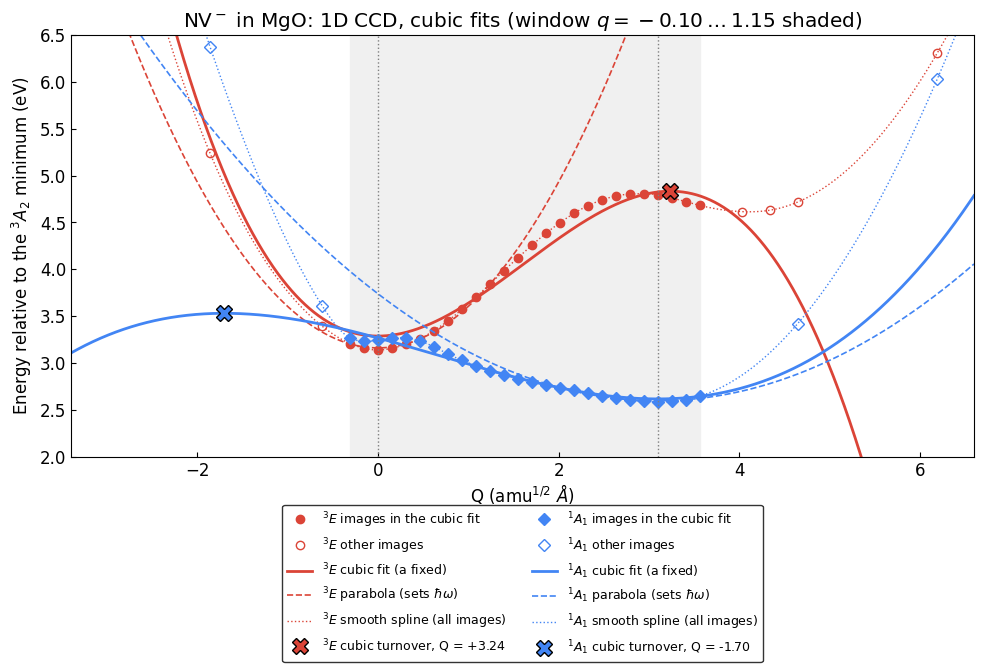

In [3]:
fig, ax = plt.subplots(figsize=(10, 7))
x = np.linspace(-3.4, 6.6, 2000)
for s, color, marker in (("3E", red, "o"), ("1A1", blue, "D")):
    d = st[s]
    label = r"$^3E$" if s == "3E" else r"$^1A_1$"
    used = d["cubic"].index
    other = np.setdiff1d(np.arange(len(d["Q"])), used)
    ax.plot(d["Q"][used], d["e"][used], marker, color=color, ms=6, ls="", label="%s images in the cubic fit" % label)
    ax.plot(d["Q"][other], d["e"][other], marker, mfc="white", mec=color, ms=6, ls="", label="%s other images" % label)
    ax.plot(x, d["cubic"](x), color=color, lw=2, label="%s cubic fit (a fixed)" % label)
    ax.plot(x, d["parabola"](x), color=color, lw=1.2, ls="--", label="%s parabola (sets $\\hbar\\omega$)" % label)
    ax.plot(x, d["spline"](x), color=color, lw=1, ls=":", label="%s smooth spline (all images)" % label)
    q_t = d["cubic"].params["turnover"]
    ax.plot([q_t], [d["cubic"](np.array([q_t]))[0]], "X", color=color, ms=12, mec="k",
            label="%s cubic turnover, Q = %+.2f" % (label, q_t))
for xv in (0.0, delta_q):
    ax.axvline(xv, color="gray", ls=":", lw=1)
ax.axvspan(-0.10 * delta_q, 1.15 * delta_q, color="0.94", zorder=0)
ax.set_xlim(x[0], x[-1])
ax.set_ylim(2.0, 6.5)
ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
ax.set_ylabel(r"Energy relative to the $^3A_2$ minimum (eV)")
ax.set_title(r"NV$^-$ in MgO: 1D CCD, cubic fits (window $q = -0.10 \dots 1.15$ shaded)")
ax.xaxis.labelpad = 2
ax.legend(fontsize=9, ncol=2, edgecolor="black", loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

Compare with the first figure of Tutorial 004, where parabola, cubic and data were indistinguishable. Here:

- the cubic misses the images in its own window by tens to a hundred meV (diamond: 0.16 meV), because the PESs are not
  cubic over $\Delta Q$: the $^3E$ curve rises to a maximum near $q \approx 0.95$, and the $^1A_1$ curve has a shoulder near
  $q \approx 0$;
- the **turnover of each cubic lies inside the range of the images** ($^3E$ at $Q \approx 3.2$, $^1A_1$ at $Q \approx -1.7$),
  i.e. inside the region where the vibrational states live. Beyond it the cubic falls to $-\infty$.

## 2. Strength of the anharmonicity and the reliable levels

3E : xi = -0.0095 (diamond: ~1e-3), n_valid = 1, Huang-Rhys factor S = 69.8, mixing at n = S: 17.1
1A1: xi = +0.0089 (diamond: ~1e-3), n_valid = 1, Huang-Rhys factor S = 36.2, mixing at n = S: 6.1


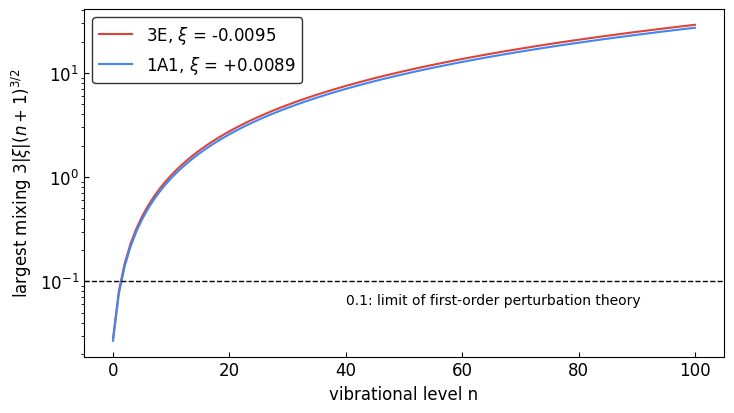

In [4]:
n = np.arange(0, 101)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for s, color in (("3E", red), ("1A1", blue)):
    d = st[s]
    d["xi"] = SUB.anharmonic_strength(d["cubic"].params["b"], d["phonon"])
    d["S"] = SUB.huang_rhys(d["phonon"], delta_q)
    mixing = 3 * abs(d["xi"]) * (n + 1) ** 1.5
    d["n_valid"] = int(np.sum(mixing <= 0.1)) - 1
    print("%-3s: xi = %+.4f (diamond: ~1e-3), n_valid = %d, Huang-Rhys factor S = %.1f, mixing at n = S: %.1f"
          % (s, d["xi"], d["n_valid"], d["S"], 3 * abs(d["xi"]) * (d["S"] + 1) ** 1.5))
    ax.semilogy(n, mixing, color=color, label=r"%s, $\xi$ = %+.4f" % (s, d["xi"]))
ax.axhline(0.1, color="k", ls="--", lw=1)
ax.text(40, 0.06, "0.1: limit of first-order perturbation theory", fontsize=10)
ax.set_xlabel("vibrational level n")
ax.set_ylabel(r"largest mixing $3|\xi|(n+1)^{3/2}$")
ax.legend(edgecolor="black")
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

$|\xi|$ is about ten times larger than in diamond, and the correction is strictly first order only for $n \le 1$. The
Huang-Rhys factors are 36-70, so the VOF of the transition is carried by final $^1A_1$ levels near $j \sim S$, where the
mixing is several units, far outside the regime.

## 3. Corrected wavefunctions

In Tutorial 004 the corrected states were compared with the exact eigenstates of the cubic. Here the cubic has **no bound
states at all**: its turnover is inside the region the levels occupy. An "exact" solution exists only in a box that cuts
the potential off before the turnover, and only for levels below the barrier (the barrier is
$\hbar\Omega/432\xi^2$, about 29 $\hbar\Omega$ for $^1A_1$). We compare, for $^1A_1$:

- the harmonic state, the first-order PT state, the cubic in a box (wall at $Q = -1.3$, inside the turnover at $-1.70$),
- and the eigenstate of the smooth spline, which describes the actual PES.

In [5]:
d = st["1A1"]
omega, xi_f, c_f = d["phonon"], d["xi"], d["center"]
q = np.linspace(-1.3, 9.0, 20001)
h = grid_spacing(q)
n_max = 30
_, psi_box = SUB.solve_schrodinger_fd(d["cubic"](q), q, n_max + 1)
_, psi_spl = SUB.solve_schrodinger_fd(d["spline"](q), q, n_max + 1)
chi = SUB.harmonic_wavefunctions(q, n_max + 3, omega, c_f)
psi_pt = SUB.cubic_correction_coefficients(n_max + 1, xi_f) @ chi


def infidelity(psi, ref):
    return 1.0 - abs(np.sum(psi * ref) * h) / np.sqrt(np.sum(psi**2) * h * np.sum(ref**2) * h)


print("1A1: 1 - |<psi|psi_ref>| (normalized)")
print("  n   mixing   | vs cubic in a box:  harmonic      PT    | vs spline (actual PES):  harmonic      PT     <psi_pt|psi_pt> - 1")
for v in (0, 1, 3, 5, 10, 20, 30):
    print("%3d   %6.2f   |                   %8.2e  %8.2e |                        %8.2e  %8.2e   %10.2e"
          % (v, 3 * abs(xi_f) * (v + 1) ** 1.5, infidelity(chi[v], psi_box[v]), infidelity(psi_pt[v], psi_box[v]),
             infidelity(chi[v], psi_spl[v]), infidelity(psi_pt[v], psi_spl[v]), np.sum(psi_pt[v] ** 2) * h - 1))

1A1: 1 - |<psi|psi_ref>| (normalized)
  n   mixing   | vs cubic in a box:  harmonic      PT    | vs spline (actual PES):  harmonic      PT     <psi_pt|psi_pt> - 1
  0     0.03   |                   3.92e-04  1.46e-06 |                        8.99e-03  7.16e-03     7.72e-04
  1     0.08   |                   3.42e-03  2.59e-05 |                        4.06e-02  2.50e-02     6.68e-03
  3     0.21   |                   3.45e-02  7.12e-04 |                        2.82e-01  1.46e-01     6.65e-02
  5     0.39   |                   1.29e-01  6.25e-03 |                        8.19e-01  4.77e-01     2.49e-01
 10     0.98   |                   7.78e-01  1.91e-01 |                        7.45e-01  5.33e-01     1.70e+00
 20     2.58   |                   9.93e-01  4.91e-01 |                        8.31e-01  6.78e-01     1.26e+01
 30     4.63   |                   9.29e-01  7.66e-01 |                        8.53e-01  7.18e-01     4.13e+01


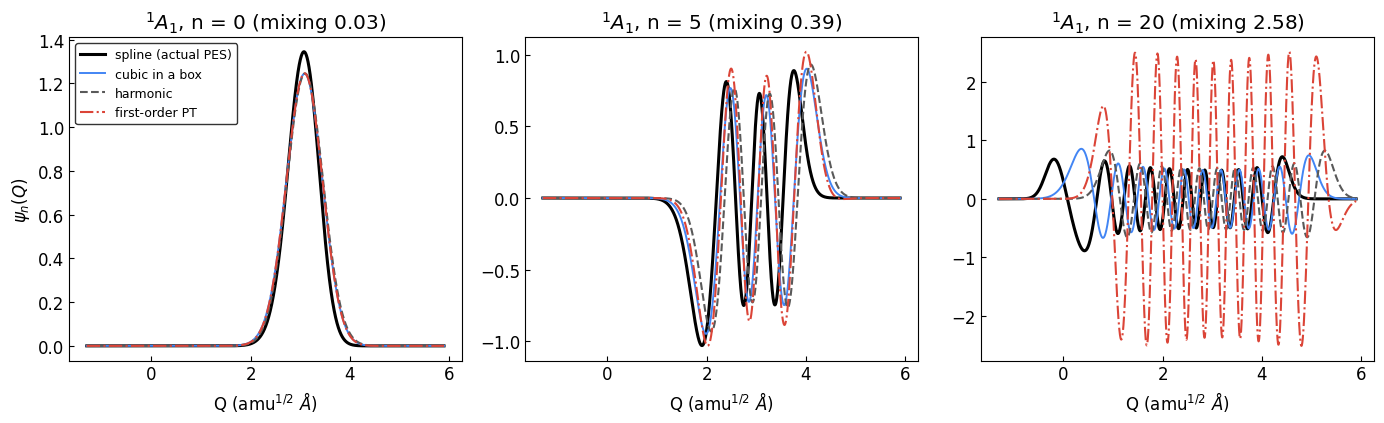

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, v in zip(axes, (0, 5, 20)):
    sel = q < c_f + 2.8
    ax.plot(q[sel], psi_spl[v][sel], color="k", lw=2.2, label="spline (actual PES)")
    ax.plot(q[sel], psi_box[v][sel], color=blue, lw=1.4, label="cubic in a box")
    ax.plot(q[sel], chi[v][sel], color=gray, ls="--", label="harmonic")
    ax.plot(q[sel], psi_pt[v][sel], color=red, ls="-.", label="first-order PT")
    ax.set_title(r"$^1A_1$, n = %d (mixing %.2f)" % (v, 3 * abs(xi_f) * (v + 1) ** 1.5))
    ax.set_xlabel(r"Q (amu$^{1/2}$ $\AA$)")
    ax.tick_params(direction="in")
axes[0].set_ylabel(r"$\psi_n(Q)$")
axes[0].legend(fontsize=9, edgecolor="black")
plt.tight_layout()
plt.show()

At $n = 0$ (mixing 0.03) PT does approach the cubic-in-a-box state, as it should (infidelity $4\times10^{-4} \rightarrow
1.5\times10^{-6}$). But the cubic itself is not the PES: against the spline state PT barely improves on the harmonic one
already at $n = 0$ ($7\times10^{-3}$ vs $9\times10^{-3}$), and from $n \approx 3$ the spline states, which live in the
actual, much more anharmonic well, are entirely different (infidelity 0.1-0.8). By $n = 5$ the mixing is about 0.4, and by
$n = 20$ the first-order state has about 13 times too much norm and resembles none of the others.

## 4. Franck-Condon integrals and the VOF

As in Tutorial 004, the VOF of the transition (emission from $^3E$, $T = 5$ K, so only $i = 0$ is populated) from

- **harmonic**: Hermite quadrature on the parabolas (identical to PyPL's Ruhoff solver at 5 K; Hermite is used because
  the Ruhoff recurrence loses accuracy in rows $i > 0$ at these Huang-Rhys factors);
- **first-order PT** on the fitted cubics;
- **exact cubic**: `compute_franck_condon_integrals_fd` on the same cubics;
- **spline**: `compute_franck_condon_integrals_fd` on the smooth splines, the reference of Tutorial 003.

All use `bulid_fc_lsp` (harmonic line positions, constant 6-8 meV broadening, Gaussian ZPL), so the comparison isolates the
Franck-Condon factors. 100 final levels close the sum $\sum_j |F_{0j}|^2$ to $10^{-6}$ in the harmonic case.

In [7]:
ni, nf = 4, 100
axis = np.linspace(0, 2000, 2001)
lsp = dict(eneaxis=axis, temp=5, sigma=[6, 8], zpl_lorentzian=False)
w_i, w_f = st["3E"]["phonon"], st["1A1"]["phonon"]
b_i, b_f = st["3E"]["cubic"].params["b"], st["1A1"]["cubic"].params["b"]


def cubic_wells(scale):
    return [lambda x, p=st[s]["cubic"].params, c=st[s]["center"]: p["a"] * (x - c) ** 2 + scale * p["b"] * (x - c) ** 3
            for s in ("3E", "1A1")]


def vof(route, scale=1.0, verbose=False):
    solver = SUB(w_i, w_f, delta_q)
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        if route == "harmonic":
            solver.compute_franck_condon_integrals_hermite(ni, nf)
        elif route == "PT":
            solver.compute_franck_condon_integrals_cubic(ni, nf, scale * b_i, scale * b_f, q_i=0.0, q_f=delta_q)
        elif route == "exact cubic":
            solver.compute_franck_condon_integrals_fd(ni, nf, *cubic_wells(scale), q_i=0.0, q_f=delta_q, npts=40001)
        elif route == "spline":
            solver.compute_franck_condon_integrals_fd(ni, nf, st["3E"]["spline"], st["1A1"]["spline"], q_i=0.0, q_f=delta_q,
                                                      npts=40001)
        solver.bulid_fc_lsp(**lsp)
    if verbose:
        print("\n".join(line for line in log.getvalue().splitlines() if line.startswith("Warning")))
    return solver


res = {route: vof(route, verbose=route == "PT") for route in ("harmonic", "PT", "exact cubic", "spline")}
print()
print("%-12s %18s %16s %14s %16s" % ("route", "sum_j |F_0j|^2", "VOF integral", "peak (meV)", "centroid (meV)"))
for route, s in res.items():
    L = s.fc_lineshape
    print("%-12s %18.4f %16.4f %14.0f %16.0f" % (route, np.sum(s.fc_ints[0] ** 2), np.trapezoid(L, axis), axis[np.argmax(L)],
                                                 np.sum(axis * L) / max(np.sum(L), 1e-300)))
ex = res["exact cubic"]
print("\nexact cubic: lowest 3E level %.2f eV, lowest 1A1 level %.3f eV (the wells' minima are at %.2f and %.2f eV)"
      % (ex.fd_energies_i[0], ex.fd_energies_f[0], st["3E"]["cubic"].params["c"], st["1A1"]["cubic"].params["c"]))
print("its grid spans Q = %.2f..%.2f, past the 3E turnover at %.2f" % (*ex.fd_info["q_range"], st["3E"]["cubic"].params["turnover"]))


route            sum_j |F_0j|^2     VOF integral     peak (meV)   centroid (meV)
harmonic                 1.0000           1.0000           1145             1146
PT                       4.5164           4.5164           1013             1112
exact cubic              0.0000           0.0000            505             1097
spline                   1.0000           1.0000            569              579

exact cubic: lowest 3E level -49.15 eV, lowest 1A1 level 0.016 eV (the wells' minima are at 3.29 and 2.62 eV)
its grid spans Q = -2.69..10.23, past the 3E turnover at 3.24


Every number in this table says the same thing:

- **First-order PT is not normalized.** $\sum_j |F_{0j}|^2$, which must be 1 for any set of final states, is several
  times larger: the corrected $^1A_1$ states with $j \sim S$ have norms far above 1 (their mixing is several units), so
  the VOF integrates to the same wrong value.
- **The "exact cubic" has no bound states.** The finite-difference grid has to reach the high $^1A_1$ levels, so it
  extends past the $^3E$ turnover. The lowest $^3E$ "level" then lies tens of eV *below* the well, in the region where the
  cubic falls to $-\infty$, held only by the wall of the box. Its overlaps with $^1A_1$ vanish. This is not a numerical
  failure but the correct answer for an unbounded potential.
- The harmonic and spline VOFs are normalized, but their peaks differ by about 580 meV (Tutorial 003),
  which is the real anharmonic effect of these PESs.

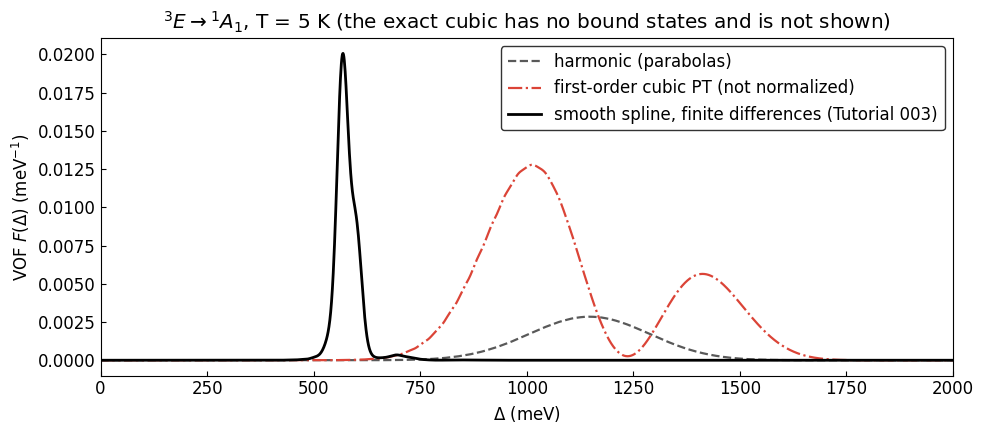

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(axis, res["harmonic"].fc_lineshape, color=gray, ls="--", lw=1.6, label="harmonic (parabolas)")
ax.plot(axis, res["PT"].fc_lineshape, color=red, ls="-.", lw=1.6, label="first-order cubic PT (not normalized)")
ax.plot(axis, res["spline"].fc_lineshape, color="k", lw=2, label="smooth spline, finite differences (Tutorial 003)")
ax.set_xlim(0, 2000)
ax.set_xlabel(r"$\Delta$ (meV)")
ax.set_ylabel(r"VOF $F(\Delta)$ (meV$^{-1}$)")
ax.set_title(r"$^3E \rightarrow {}^1A_1$, T = 5 K (the exact cubic has no bound states and is not shown)")
ax.legend(edgecolor="black")
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

## 5. When would the perturbative correction be valid here?

### 5.1 Which levels carry the VOF

At 5 K the VOF is $\sum_j |F_{0j}|^2 \delta(\Delta - E_j)$. The initial level $i = 0$ of $^3E$ is inside the regime
(mixing $3|\xi_{^3E}| \approx 0.03$), so everything depends on the final $^1A_1$ levels that carry the weight:

weight-averaged mixing of the final levels: harmonic weights 6.1, spline weights 2.3
weight in final levels with mixing <= 0.1 (j <= 1): harmonic 1.2e-19, spline 8.6e-19


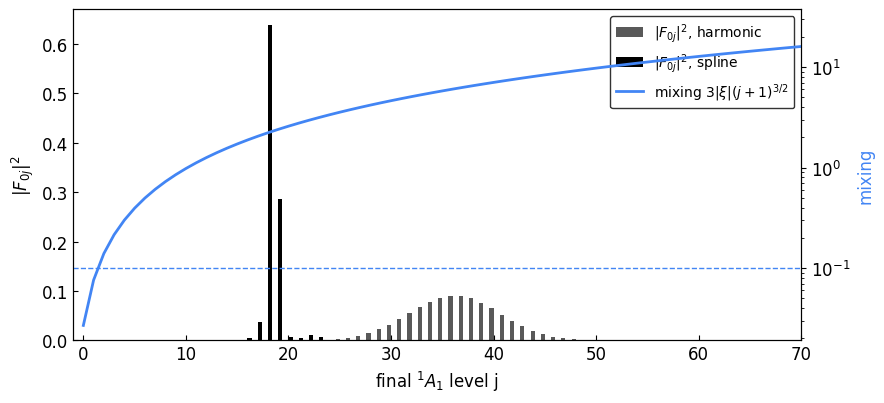

In [9]:
j = np.arange(nf)
mu_f = 3 * abs(st["1A1"]["xi"]) * (j + 1) ** 1.5
w_harm, w_spl = res["harmonic"].fc_ints[0] ** 2, res["spline"].fc_ints[0] ** 2
print("weight-averaged mixing of the final levels: harmonic weights %.1f, spline weights %.1f"
      % (np.sum(w_harm * mu_f), np.sum(w_spl * mu_f) / np.sum(w_spl)))
print("weight in final levels with mixing <= 0.1 (j <= %d): harmonic %.1e, spline %.1e"
      % (st["1A1"]["n_valid"], w_harm[mu_f <= 0.1].sum(), w_spl[mu_f <= 0.1].sum()))

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(j - 0.2, w_harm, width=0.4, color=gray, label=r"$|F_{0j}|^2$, harmonic")
ax.bar(j + 0.2, w_spl, width=0.4, color="k", label=r"$|F_{0j}|^2$, spline")
ax.set_xlabel(r"final $^1A_1$ level j")
ax.set_ylabel(r"$|F_{0j}|^2$")
ax.set_xlim(-1, 70)
ax2 = ax.twinx()
ax2.semilogy(j, mu_f, color=blue, lw=2, label=r"mixing $3|\xi|(j+1)^{3/2}$")
ax2.axhline(0.1, color=blue, ls="--", lw=1)
ax2.set_ylabel("mixing", color=blue)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, edgecolor="black", loc="upper right", fontsize=10)
ax.tick_params(direction="in")
plt.tight_layout()
plt.show()

Essentially none of the weight is in levels where the correction is valid: with harmonic weights the VOF is carried by
$j \approx 20$-$50$, with mixing between 2 and 10. (With the spline, the weight concentrates on two levels near
$j \approx 18$-$19$ that sit in the shoulder of the $^1A_1$ PES, Tutorial 003; still far outside the regime.)

### 5.2 Scaling with $b$: how much weaker would the anharmonicity have to be?

As in Tutorial 004, both fitted $b$ are scaled by $s$ and the VOF from PT is compared with the exact solution of the scaled
cubics. The exact solution exists only while the turnovers stay outside the finite-difference grid, which here means
$s \le 1/4$.

s = 1/64 : anharmonic effect 3.46e-02, PT error 1.64e-03 (captures  95 %), PT sum_j |F_0j|^2 = 1.001, mixing at j = S: 0.10
s = 1/32 : anharmonic effect 6.91e-02, PT error 6.51e-03 (captures  91 %), PT sum_j |F_0j|^2 = 1.003, mixing at j = S: 0.19
s = 1/16 : anharmonic effect 1.37e-01, PT error 2.56e-02 (captures  81 %), PT sum_j |F_0j|^2 = 1.014, mixing at j = S: 0.38
s = 1/8  : anharmonic effect 2.67e-01, PT error 9.94e-02 (captures  63 %), PT sum_j |F_0j|^2 = 1.055, mixing at j = S: 0.76
s = 1/4  : anharmonic effect 4.98e-01, PT error 3.72e-01 (captures  25 %), PT sum_j |F_0j|^2 = 1.220, mixing at j = S: 1.52
s = 1/2  : a turnover (3E 6.48, 1A1 -6.50) is inside the grid Q = -2.69..10.23 -> no bound states, skipped


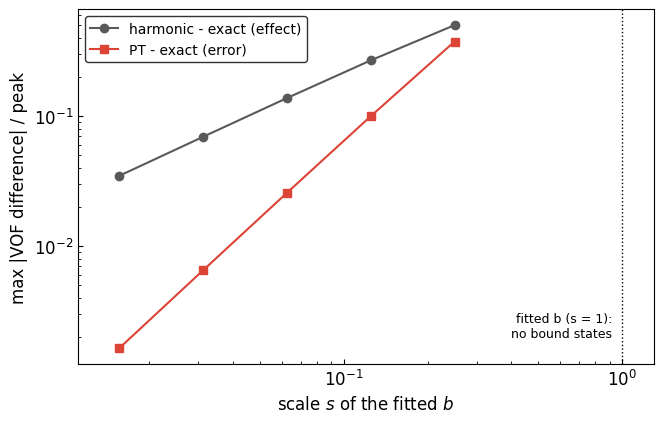

In [10]:
scales = np.array([1 / 64, 1 / 32, 1 / 16, 1 / 8, 1 / 4, 1 / 2])
q_lo, q_hi = res["spline"].fd_info["q_range"]
rows = []
for s in scales:
    turn = {k: st[k]["center"] + (st[k]["cubic"].params["turnover"] - st[k]["center"]) / s for k in ("3E", "1A1")}
    inside = any(q_lo < t < q_hi for t in turn.values())
    if inside:
        print("s = 1/%-3d: a turnover (3E %.2f, 1A1 %.2f) is inside the grid Q = %.2f..%.2f -> no bound states, skipped"
              % (round(1 / s), turn["3E"], turn["1A1"], q_lo, q_hi))
        continue
    pt_s, ex_s = vof("PT", s), vof("exact cubic", s)
    peak = ex_s.fc_lineshape.max()
    effect = np.max(np.abs(res["harmonic"].fc_lineshape - ex_s.fc_lineshape)) / peak
    error = np.max(np.abs(pt_s.fc_lineshape - ex_s.fc_lineshape)) / peak
    rows.append((s, effect, error, np.sum(pt_s.fc_ints[0] ** 2), 3 * abs(st["1A1"]["xi"]) * s * (st["1A1"]["S"] + 1) ** 1.5))
    print("s = 1/%-3d: anharmonic effect %.2e, PT error %.2e (captures %3.0f %%), PT sum_j |F_0j|^2 = %.3f, mixing at j = S: %.2f"
          % (round(1 / s), effect, error, 100 * (1 - error / effect), rows[-1][3], rows[-1][4]))
rows = np.array(rows)

fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.loglog(rows[:, 0], rows[:, 1], "o-", color=gray, label="harmonic - exact (effect)")
ax.loglog(rows[:, 0], rows[:, 2], "s-", color=red, label="PT - exact (error)")
ax.axvline(1.0, color="k", ls=":", lw=1)
ax.text(0.92, 2e-3, "fitted b (s = 1):\nno bound states", ha="right", fontsize=9)
ax.set_xlim(1 / 90, 1.3)
ax.set_xlabel(r"scale $s$ of the fitted $b$")
ax.set_ylabel("max |VOF difference| / peak")
ax.legend(fontsize=10, edgecolor="black")
ax.tick_params(direction="in", which="both")
plt.tight_layout()
plt.show()

The behaviour of Tutorial 004 is recovered only at small $s$: the PT error falls as $s^2$ and the effect as $s$. PT captures
90 % or more of the cubic effect only for $s \lesssim 1/32$, i.e. if the cubic anharmonicity were **about 30 times weaker**
than fitted; at $s = 1/4$ the error is comparable to the effect (25 % captured), and from $s = 1/2$ there is no bound
solution to compare with. The criterion of Tutorial 004 predicts this: the mixing at the levels that carry the VOF
($j \approx S$) falls to $\sim 0.1$-$0.2$ only for $s \approx 1/64$-$1/32$.

### 5.3 The three conditions of Tutorial 004, supplementary S4

In [11]:
print("%-4s %8s %8s %10s %16s %18s %18s %14s" % ("", "xi", "n_valid", "mix(n=S)", "E2(n=S)/hw", "|Q_t - Q_0| (A)", "levels below barrier", "Q_t in images"))
for s, d in st.items():
    x, S = d["xi"], d["S"]
    p = d["cubic"].params
    e2 = x**2 * (30 * S**2 + 30 * S + 11)
    print("%-4s %+8.4f %8d %10.1f %16.1f %18.2f %18.0f %14s" % (s, x, d["n_valid"], 3 * abs(x) * (S + 1) ** 1.5, e2,
          abs(p["turnover"] - d["center"]), 1 / (432 * x**2), d["Q"].min() < p["turnover"] < d["Q"].max()))

           xi  n_valid   mix(n=S)       E2(n=S)/hw    |Q_t - Q_0| (A) levels below barrier  Q_t in images
3E    -0.0095        1       17.1             13.5               3.24                 25           True
1A1   +0.0089        1        6.1              3.2               4.80                 29           True


All three conditions fail at the levels that matter:

1. **Mixing** at $n \approx S$ is several units, against the limit 0.1 ($n_\mathrm{valid} = 1$).
2. **The second-order energy shift** $|E^{(2)}_n|$ at $n \approx S$ is of the order of $\hbar\Omega$ or more, so even the
   harmonic ladder that `bulid_fc_lsp` assumes is wrong.
3. **The bound region**: the barrier holds about 25-30 levels, fewer than the Huang-Rhys factors, and the turnover is
   inside the sampled path.

## 6. Summary

| | NV$^-$ in diamond (Tutorial 004) | NV$^-$ in MgO (this notebook) |
| --- | --- | --- |
| cubic rms in its window | 0.16 meV | 40-110 meV |
| $\lvert\xi\rvert$ | $\approx 10^{-3}$ | $\approx 10^{-2}$ |
| Huang-Rhys factors | 3.4, 3.7 | 36, 70 |
| $n_\mathrm{valid}$ / levels carrying the VOF | 8-9 / $j \lesssim 10$ | 1 / $j \approx 20$-$50$ |
| turnover | tens of amu$^{1/2}$ Å away | inside the images |
| $\sum_j \lvert F_{0j}\rvert^2$ from PT | 1.00 | several (unphysical) |
| PT vs exact cubic VOF | 99 % of the effect | no bound exact solution; PT valid only for $b/30$ |

For a strongly anharmonic system like NV$^-$ in MgO, a low-order expansion of the PES around one minimum cannot describe
the levels that carry the transition, and perturbation theory on top of it fails by every measure. The appropriate route
is a non-perturbative solution on a faithful fit of all the data: `compute_franck_condon_integrals_fd` on the smooth
not-a-knot spline, with `build_fc_lsp_from_levels` for the line positions, as in Tutorial 003.